# Data Analysis: Conspiracy Theory Annotation Corpus

This notebook provides comprehensive analysis of the Telegram posts dataset annotated for conspiracy theory detection.


In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set working directory to project root
import os
os.chdir('/home/ashrafs/projects/Conspiracy-Proj')
print(f"Working directory: {os.getcwd()}")

# Set plotting style
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    try:
        plt.style.use('seaborn-darkgrid')
    except:
        pass
sns.set_palette("husl")
%matplotlib inline

# Create plots directory
Path('plots').mkdir(exist_ok=True)
print('Libraries imported successfully!')


Working directory: /home/ashrafs/projects/Conspiracy-Proj
Libraries imported successfully!


## 1. Load Data


In [ ]:
# Load datasets
df_classifications = pd.read_csv('Data/all_classifications.csv')
df_span_annotations = pd.read_csv('Data/all_span_annotations.csv')

print("Classifications shape:", df_classifications.shape)
print("Span annotations shape:", df_span_annotations.shape)
print("\nClassifications columns:", df_classifications.columns.tolist())
print("\nSpan annotations columns (first 10):", df_span_annotations.columns.tolist()[:10])
print("\nData loaded successfully!")


Classifications shape: (3243, 7)
Span annotations shape: (934, 56)

Classifications columns: ['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative']

Span annotations columns (first 10): ['annotator_id', 'text_id', 'annotation_id', 'text', 'out-group', 'plan', 'call-to-action', 'in-group', 'secret', 'This is a clear and direct expression of a classic anti-Semitic conspiracy theory. The deliberate poisoning of food and water by a specific Out-group which is jews. This plan is presented as a direct threat to the health and well-being of the implied In-group.']

Data loaded successfully!


In [ ]:
# Display first few rows
print("Classifications dataset preview:")
print(df_classifications.head())
print("\n" + "="*80 + "\n")
print("Span annotations dataset preview:")
print(df_span_annotations.head())


Classifications dataset preview:
   annotator_id  text_id  annotation_id  \
0           161    21580          33266   
1           161    21581          33268   
2           161    21634          33409   
3           161    21649          33446   
4           161    21653          33458   

                                                text conspiracy supportive  \
0  Someone should comment this under Elon Musks C...         no        yes   
1  WLM viewing #4\n\nThe rule of Nature\nMandator...         no         no   
2  Imagine being a Normie waking up everyday not ...         no         no   
3  Activism finally out and about in Australia\n\...         no         no   
4  One of our activists was out delivering 500 Eu...         no         no   

  misinformative  
0            NaN  
1            NaN  
2            NaN  
3            NaN  
4            NaN  


Span annotations dataset preview:
   annotator_id  text_id  annotation_id  \
0           161    21656          33463   
1  

## 2. Basic Statistics


In [ ]:
# How many posts are annotated in all_classifications.csv
total_annotations = len(df_classifications)
unique_posts = df_classifications['text_id'].nunique()

print("="*60)
print("BASIC STATISTICS")
print("="*60)
print(f"Total number of annotations: {total_annotations:,}")
print(f"Total number of unique posts annotated: {unique_posts:,}")
print(f"Average annotations per post: {total_annotations/unique_posts:.2f}")
print("="*60)


BASIC STATISTICS
Total number of annotations: 3,243
Total number of unique posts annotated: 2,077
Average annotations per post: 1.56


In [ ]:
# Posts distribution for label conspiracy
conspiracy_dist = df_classifications['conspiracy'].value_counts()

print("\nPosts distribution for label 'conspiracy':")
print("-" * 60)
print(conspiracy_dist)
print("\nPercentage distribution:")
conspiracy_pct = (conspiracy_dist / len(df_classifications) * 100).round(2)
print(conspiracy_pct)
print("=" * 60)



Posts distribution for label 'conspiracy':
------------------------------------------------------------
conspiracy
no     2497
yes     669
Name: count, dtype: int64

Percentage distribution:
conspiracy
no     77.00
yes    20.63
Name: count, dtype: float64


In [ ]:
# Posts distribution for label supportive
supportive_dist = df_classifications['supportive'].value_counts()

print("\nPosts distribution for label 'supportive':")
print("-" * 60)
print(supportive_dist)
print("\nPercentage distribution:")
supportive_pct = (supportive_dist / len(df_classifications) * 100).round(2)
print(supportive_pct)
print("=" * 60)



Posts distribution for label 'supportive':
------------------------------------------------------------
supportive
no     1699
yes    1447
Name: count, dtype: int64

Percentage distribution:
supportive
no     52.39
yes    44.62
Name: count, dtype: float64


✓ Plot saved to plots/label_distributions.png


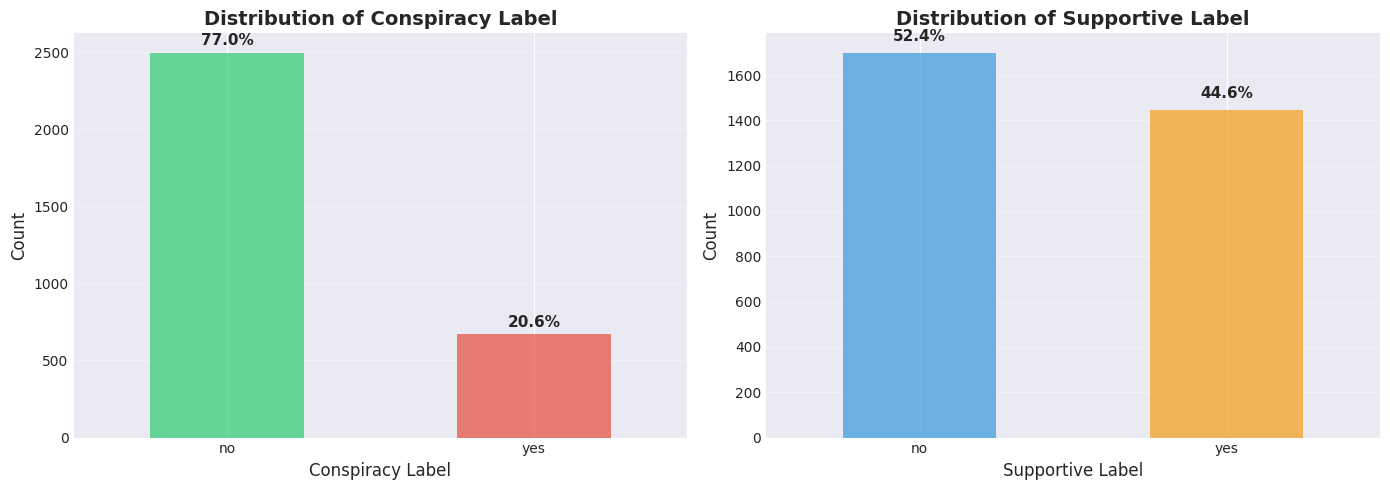

In [ ]:
# Visualization: Distribution of conspiracy and supportive labels
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Conspiracy distribution
conspiracy_dist.plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'], alpha=0.7)
axes[0].set_title('Distribution of Conspiracy Label', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Conspiracy Label', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Add percentage labels
for i, (idx, val) in enumerate(conspiracy_dist.items()):
    pct = val / len(df_classifications) * 100
    axes[0].text(i, val + 50, f'{pct:.1f}%', ha='center', fontsize=11, fontweight='bold')

# Supportive distribution
supportive_dist.plot(kind='bar', ax=axes[1], color=['#3498db', '#f39c12'], alpha=0.7)
axes[1].set_title('Distribution of Supportive Label', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Supportive Label', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', alpha=0.3)

# Add percentage labels
for i, (idx, val) in enumerate(supportive_dist.items()):
    pct = val / len(df_classifications) * 100
    axes[1].text(i, val + 50, f'{pct:.1f}%', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/label_distributions.png', dpi=300, bbox_inches='tight')
print('✓ Plot saved to plots/label_distributions.png')
plt.show()


In [ ]:
# Check for posts with both Conspiracy='yes' and Supportive='yes'
both_yes = df_classifications[(df_classifications['conspiracy'] == 'yes') & 
                               (df_classifications['supportive'] == 'yes')]

print("="*60)
print("POSTS WITH BOTH CONSPIRACY='YES' AND SUPPORTIVE='YES'")
print("="*60)
print(f"Number of annotations with both labels 'yes': {len(both_yes):,}")
print(f"Percentage of total annotations: {len(both_yes)/len(df_classifications)*100:.2f}%")
print(f"\nNumber of unique posts with both labels 'yes': {both_yes['text_id'].nunique():,}")
print("="*60)

if len(both_yes) > 0:
    print("\nSample of posts with both labels:")
    print(both_yes[['text_id', 'annotator_id', 'conspiracy', 'supportive']].head(10))
else:
    print("\nNo posts found with both Conspiracy='yes' and Supportive='yes'")


POSTS WITH BOTH CONSPIRACY='YES' AND SUPPORTIVE='YES'
Number of annotations with both labels 'yes': 585
Percentage of total annotations: 18.04%

Number of unique posts with both labels 'yes': 491

Sample of posts with both labels:
    text_id  annotator_id conspiracy supportive
14    21616           161        yes        yes
15    21595           161        yes        yes
18    21667           161        yes        yes
19    21631           161        yes        yes
23    21670           161        yes        yes
32    21629           161        yes        yes
36    21673           161        yes        yes
41    21608           161        yes        yes
45    21651           161        yes        yes
46    21602           161        yes        yes


In [ ]:
# Cross-tabulation: Conspiracy vs Supportive
crosstab = pd.crosstab(df_classifications['conspiracy'], 
                       df_classifications['supportive'], 
                       margins=True)

print("Cross-tabulation: Conspiracy vs Supportive")
print("="*60)
print(crosstab)
print("\nPercentage breakdown:")
crosstab_pct = pd.crosstab(df_classifications['conspiracy'], 
                           df_classifications['supportive'], 
                           normalize='index') * 100
print(crosstab_pct.round(2))
print("="*60)


Cross-tabulation: Conspiracy vs Supportive
supportive    no   yes   All
conspiracy                  
no          1597   853  2450
yes           64   585   649
All         1661  1438  3099

Percentage breakdown:
supportive     no    yes
conspiracy              
no          65.18  34.82
yes          9.86  90.14


## 3. Cross-Annotation Analysis


In [ ]:
# Number of annotations per annotator
annotator_counts = df_classifications.groupby('annotator_id').size().reset_index(name='annotation_count')
annotator_counts = annotator_counts.sort_values('annotation_count', ascending=False)

print("="*60)
print("ANNOTATIONS PER ANNOTATOR")
print("="*60)
print(f"Total number of annotators: {df_classifications['annotator_id'].nunique()}")
print(f"\nAnnotations per annotator:")
print(annotator_counts)
print(f"\nAverage annotations per annotator: {annotator_counts['annotation_count'].mean():.2f}")
print(f"Median annotations per annotator: {annotator_counts['annotation_count'].median():.2f}")
print(f"Min annotations: {annotator_counts['annotation_count'].min()}")
print(f"Max annotations: {annotator_counts['annotation_count'].max()}")
print("="*60)


ANNOTATIONS PER ANNOTATOR
Total number of annotators: 13

Annotations per annotator:
    annotator_id  annotation_count
2             17               300
4             60               300
3             18               300
7            166               300
5            161               299
6            165               299
1              7               298
12           182               298
9            175               228
10           178               200
0              4               198
11           181               196
8            172                27

Average annotations per annotator: 249.46
Median annotations per annotator: 298.00
Min annotations: 27
Max annotations: 300


In [ ]:
# How many posts are annotated by 1, 2, or multiple annotators
posts_annotator_count = df_classifications.groupby('text_id')['annotator_id'].nunique().reset_index(name='num_annotators')

annotator_distribution = posts_annotator_count['num_annotators'].value_counts().sort_index()

print("="*60)
print("POSTS BY NUMBER OF ANNOTATORS")
print("="*60)
print("Number of posts annotated by N annotators:")
print(annotator_distribution)
print("\nPercentage distribution:")
annotator_distribution_pct = (annotator_distribution / len(posts_annotator_count) * 100).round(2)
print(annotator_distribution_pct)
print("\nSummary:")
print(f"  Posts with 1 annotator: {(posts_annotator_count['num_annotators'] == 1).sum():,}")
print(f"  Posts with 2+ annotators (cross-annotated): {(posts_annotator_count['num_annotators'] > 1).sum():,}")
print(f"  Posts with 2 annotators: {(posts_annotator_count['num_annotators'] == 2).sum():,}")
print(f"  Posts with 3+ annotators: {(posts_annotator_count['num_annotators'] >= 3).sum():,}")
print("="*60)


POSTS BY NUMBER OF ANNOTATORS
Number of posts annotated by N annotators:
num_annotators
1     911
2    1166
Name: count, dtype: int64

Percentage distribution:
num_annotators
1    43.86
2    56.14
Name: count, dtype: float64

Summary:
  Posts with 1 annotator: 911
  Posts with 2+ annotators (cross-annotated): 1,166
  Posts with 2 annotators: 1,166
  Posts with 3+ annotators: 0


### Explanation:
- **1 annotator**: Post annotated by a single annotator
- **2 annotators**: Same post annotated by 2 different annotators (cross-annotation)
- **3+ annotators**: Same post annotated by 3 or more different annotators


In [ ]:
# Detailed breakdown: Show examples of posts with multiple annotators
print("="*60)
print("DETAILED BREAKDOWN OF CROSS-ANNOTATED POSTS")
print("="*60)

# Find posts with exactly 2 annotators
posts_with_2 = posts_annotator_count[posts_annotator_count['num_annotators'] == 2]
print(f"\nPosts with exactly 2 annotators: {len(posts_with_2):,}")

# Show which annotators worked on the same posts
sample_posts = posts_with_2.head(5)
print("\nSample posts with 2 annotators:")
for text_id in sample_posts['text_id'].head(5):
    annotators = df_classifications[df_classifications['text_id'] == text_id]['annotator_id'].unique()
    print(f"  Post {text_id}: Annotated by annotators {sorted(annotators)}")

# Check if there are any posts with 3+ annotators
posts_with_3plus = posts_annotator_count[posts_annotator_count['num_annotators'] >= 3]
if len(posts_with_3plus) > 0:
    print(f"\nPosts with 3+ annotators: {len(posts_with_3plus):,}")
    print("Sample:")
    for text_id in posts_with_3plus['text_id'].head(3):
        annotators = df_classifications[df_classifications['text_id'] == text_id]['annotator_id'].unique()
        print(f"  Post {text_id}: Annotated by annotators {sorted(annotators)}")
else:
    print("\nNo posts found with 3 or more annotators.")
    print("All cross-annotated posts have exactly 2 annotators.")

print("="*60)


DETAILED BREAKDOWN OF CROSS-ANNOTATED POSTS

Posts with exactly 2 annotators: 1,166

Sample posts with 2 annotators:
  Post 21179: Annotated by annotators [np.int64(4), np.int64(161)]
  Post 21180: Annotated by annotators [np.int64(4), np.int64(161)]
  Post 21181: Annotated by annotators [np.int64(4), np.int64(161)]
  Post 21182: Annotated by annotators [np.int64(4), np.int64(161)]
  Post 21183: Annotated by annotators [np.int64(4), np.int64(161)]

No posts found with 3 or more annotators.
All cross-annotated posts have exactly 2 annotators.


✓ Plot saved to plots/annotator_distribution.png


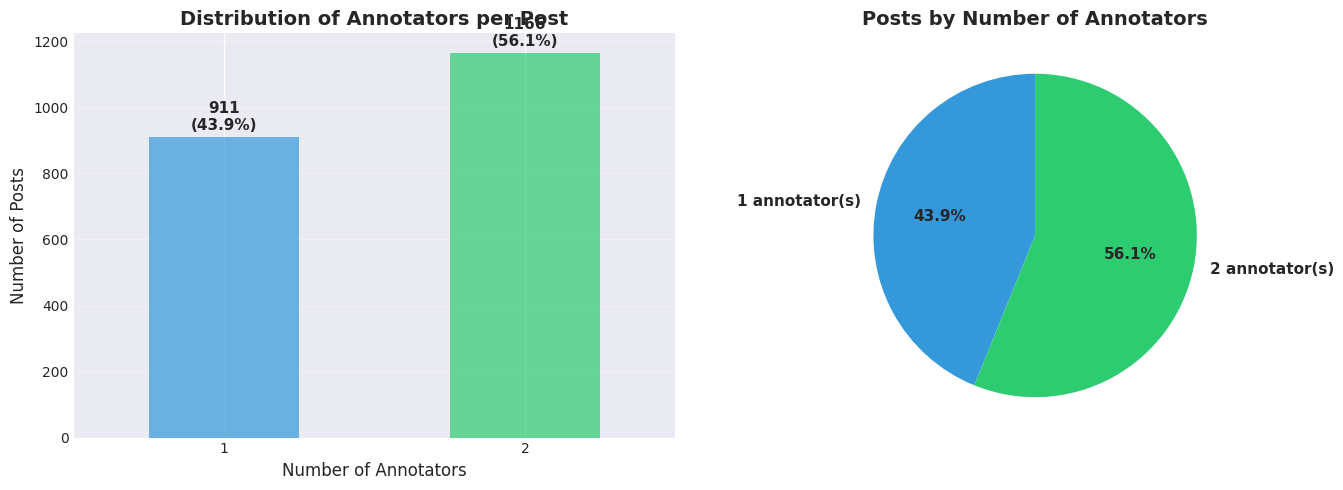

In [ ]:
# Visualization: Distribution of number of annotators per post
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
annotator_distribution.plot(kind='bar', ax=axes[0], color=['#3498db', '#2ecc71'], alpha=0.7)
axes[0].set_xlabel('Number of Annotators', fontsize=12)
axes[0].set_ylabel('Number of Posts', fontsize=12)
axes[0].set_title('Distribution of Annotators per Post', fontsize=14, fontweight='bold')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', alpha=0.3)

# Add value labels
for i, (idx, val) in enumerate(annotator_distribution.items()):
    pct = val / len(posts_annotator_count) * 100
    axes[0].text(i, val + 20, f'{val}\n({pct:.1f}%)', ha='center', fontsize=11, fontweight='bold')

# Pie chart
axes[1].pie(annotator_distribution.values, labels=[f'{i} annotator(s)' for i in annotator_distribution.index], 
            autopct='%1.1f%%', startangle=90, colors=['#3498db', '#2ecc71'], 
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Posts by Number of Annotators', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/annotator_distribution.png', dpi=300, bbox_inches='tight')
print('✓ Plot saved to plots/annotator_distribution.png')
plt.show()


## 4. Agreement Analysis (Posts with 2 Annotators)


In [ ]:
# Filter posts with exactly 2 annotators
posts_with_2_annotators = posts_annotator_count[posts_annotator_count['num_annotators'] == 2]['text_id'].values
df_cross_annotated = df_classifications[df_classifications['text_id'].isin(posts_with_2_annotators)]

print("="*60)
print("AGREEMENT ANALYSIS FOR POSTS WITH 2 ANNOTATORS")
print("="*60)
print(f"Total posts with 2 annotators: {len(posts_with_2_annotators):,}")
print(f"Total annotations for these posts: {len(df_cross_annotated):,}")
print("="*60)


AGREEMENT ANALYSIS FOR POSTS WITH 2 ANNOTATORS
Total posts with 2 annotators: 1,166
Total annotations for these posts: 2,332


In [ ]:
# Calculate agreement for conspiracy label
def calculate_agreement(group, label_col):
    """Check if all annotators agree on a label"""
    unique_labels = group[label_col].dropna().unique()
    if len(unique_labels) == 1:
        return 'Agree'
    else:
        return 'Disagree'

# Agreement for conspiracy label
conspiracy_agreement = df_cross_annotated.groupby('text_id')[['conspiracy']].apply(
    lambda x: calculate_agreement(x, 'conspiracy')
).reset_index(name='conspiracy_agreement')

# Agreement for supportive label  
supportive_agreement = df_cross_annotated.groupby('text_id')[['supportive']].apply(
    lambda x: calculate_agreement(x, 'supportive')
).reset_index(name='supportive_agreement')

# Combine results
agreement_results = pd.merge(conspiracy_agreement, supportive_agreement, on='text_id')

print("Agreement Results for Posts with 2 Annotators:")
print("-" * 60)
print("\n1. Conspiracy Label Agreement:")
conspiracy_agree_dist = agreement_results['conspiracy_agreement'].value_counts()
print(conspiracy_agree_dist)
print(f"\n   Agreement rate: {conspiracy_agree_dist.get('Agree', 0) / len(agreement_results) * 100:.2f}%")
print(f"   Disagreement rate: {conspiracy_agree_dist.get('Disagree', 0) / len(agreement_results) * 100:.2f}%")

print("\n2. Supportive Label Agreement:")
supportive_agree_dist = agreement_results['supportive_agreement'].value_counts()
print(supportive_agree_dist)
print(f"\n   Agreement rate: {supportive_agree_dist.get('Agree', 0) / len(agreement_results) * 100:.2f}%")
print(f"   Disagreement rate: {supportive_agree_dist.get('Disagree', 0) / len(agreement_results) * 100:.2f}%")
print("=" * 60)


Agreement Results for Posts with 2 Annotators:
------------------------------------------------------------

1. Conspiracy Label Agreement:
conspiracy_agreement
Agree       947
Disagree    219
Name: count, dtype: int64

   Agreement rate: 81.22%
   Disagreement rate: 18.78%

2. Supportive Label Agreement:
supportive_agreement
Agree       714
Disagree    452
Name: count, dtype: int64

   Agreement rate: 61.23%
   Disagreement rate: 38.77%


In [ ]:
# Detailed agreement patterns
print("="*60)
print("DETAILED AGREEMENT PATTERNS")
print("="*60)

# Both agree on conspiracy, both agree on supportive
both_agree = len(agreement_results[(agreement_results['conspiracy_agreement'] == 'Agree') & 
                                     (agreement_results['supportive_agreement'] == 'Agree')])
print(f"\nPosts where both annotators agree on BOTH labels:")
print(f"  Count: {both_agree:,}")
print(f"  Percentage: {both_agree / len(agreement_results) * 100:.2f}%")

# Agree on conspiracy, disagree on supportive
agree_cons_disagree_sup = len(agreement_results[(agreement_results['conspiracy_agreement'] == 'Agree') & 
                                                  (agreement_results['supportive_agreement'] == 'Disagree')])
print(f"\nPosts where annotators agree on Conspiracy but disagree on Supportive:")
print(f"  Count: {agree_cons_disagree_sup:,}")
print(f"  Percentage: {agree_cons_disagree_sup / len(agreement_results) * 100:.2f}%")

# Disagree on conspiracy, agree on supportive
disagree_cons_agree_sup = len(agreement_results[(agreement_results['conspiracy_agreement'] == 'Disagree') & 
                                                   (agreement_results['supportive_agreement'] == 'Agree')])
print(f"\nPosts where annotators disagree on Conspiracy but agree on Supportive:")
print(f"  Count: {disagree_cons_agree_sup:,}")
print(f"  Percentage: {disagree_cons_agree_sup / len(agreement_results) * 100:.2f}%")

# Both disagree
both_disagree = len(agreement_results[(agreement_results['conspiracy_agreement'] == 'Disagree') & 
                                        (agreement_results['supportive_agreement'] == 'Disagree')])
print(f"\nPosts where annotators disagree on BOTH labels:")
print(f"  Count: {both_disagree:,}")
print(f"  Percentage: {both_disagree / len(agreement_results) * 100:.2f}%")

print("="*60)


DETAILED AGREEMENT PATTERNS

Posts where both annotators agree on BOTH labels:
  Count: 590
  Percentage: 50.60%

Posts where annotators agree on Conspiracy but disagree on Supportive:
  Count: 357
  Percentage: 30.62%

Posts where annotators disagree on Conspiracy but agree on Supportive:
  Count: 124
  Percentage: 10.63%

Posts where annotators disagree on BOTH labels:
  Count: 95
  Percentage: 8.15%


✓ Plot saved to plots/agreement_analysis.png


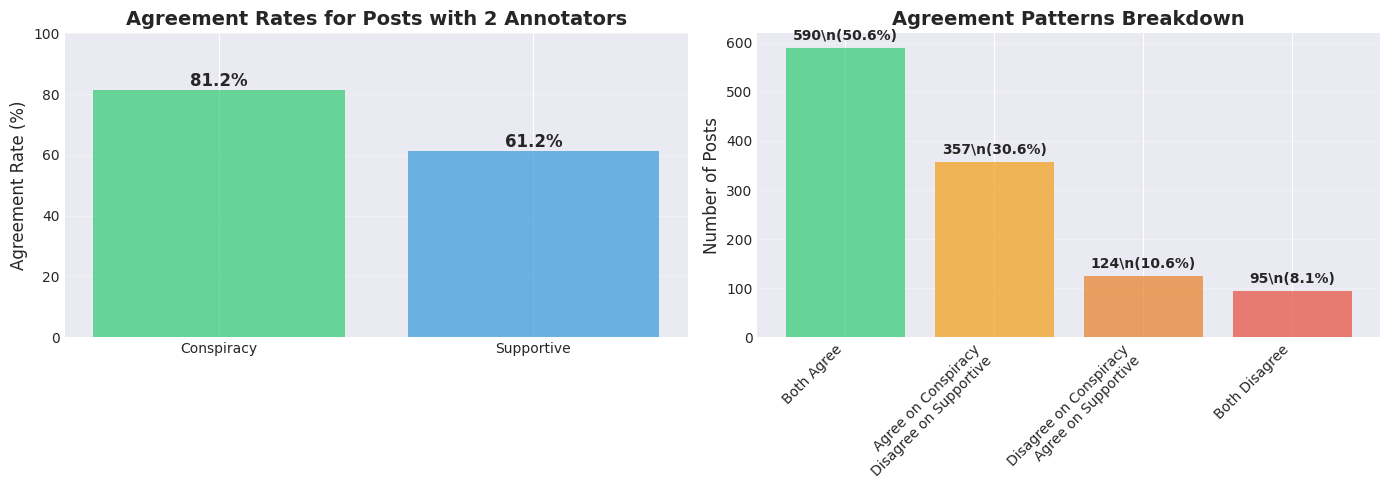

In [ ]:
# Visualization: Agreement analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Agreement rates for conspiracy and supportive
agreement_rates = {
    'Conspiracy': conspiracy_agree_dist.get('Agree', 0) / len(agreement_results) * 100,
    'Supportive': supportive_agree_dist.get('Agree', 0) / len(agreement_results) * 100
}

bars = axes[0].bar(agreement_rates.keys(), agreement_rates.values(), 
                   color=['#2ecc71', '#3498db'], alpha=0.7)
axes[0].set_ylabel('Agreement Rate (%)', fontsize=12)
axes[0].set_title('Agreement Rates for Posts with 2 Annotators', fontsize=14, fontweight='bold')
axes[0].set_ylim([0, 100])
axes[0].grid(axis='y', alpha=0.3)

# Add value labels
for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Agreement patterns
patterns = {
    'Both Agree': both_agree,
    'Agree on Conspiracy\nDisagree on Supportive': agree_cons_disagree_sup,
    'Disagree on Conspiracy\nAgree on Supportive': disagree_cons_agree_sup,
    'Both Disagree': both_disagree
}

bars2 = axes[1].bar(range(len(patterns)), list(patterns.values()), 
                   color=['#2ecc71', '#f39c12', '#e67e22', '#e74c3c'], alpha=0.7)
axes[1].set_ylabel('Number of Posts', fontsize=12)
axes[1].set_title('Agreement Patterns Breakdown', fontsize=14, fontweight='bold')
axes[1].set_xticks(range(len(patterns)))
axes[1].set_xticklabels(list(patterns.keys()), rotation=45, ha='right')
axes[1].grid(axis='y', alpha=0.3)

# Add value labels
for i, (bar, val) in enumerate(zip(bars2, patterns.values())):
    pct = val / len(agreement_results) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2., val + 10,
                f'{val}\\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/agreement_analysis.png', dpi=300, bbox_inches='tight')
print('✓ Plot saved to plots/agreement_analysis.png')
plt.show()


---

## Span Annotations Analysis

This section analyzes the span-level annotations for conspiracy theory elements.


In [ ]:
# Load span annotations data
df_spans = pd.read_csv('Data/all_span_annotations.csv')

# The 5 span elements
span_elements = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']

print(f"Total span annotation records: {len(df_spans):,}")
print(f"Unique posts with span annotations: {df_spans['text_id'].nunique():,}")
print(f"\nSpan elements columns: {span_elements}")
print("\n✓ Span annotations data loaded successfully!")


Total span annotation records: 934
Unique posts with span annotations: 755

Span elements columns: ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']

✓ Span annotations data loaded successfully!


In [ ]:
# Function to check if an element is annotated (non-empty)
def is_annotated(value):
    """Check if a span element is annotated (non-empty)"""
    if pd.isna(value):
        return False
    if isinstance(value, str) and value.strip() == '':
        return False
    return True

# Count annotated elements for each row
for col in span_elements:
    if col in df_spans.columns:
        df_spans[f'{col}_annotated'] = df_spans[col].apply(is_annotated)
    else:
        df_spans[f'{col}_annotated'] = False

# Calculate number of elements annotated per post
element_cols = [f'{elem}_annotated' for elem in span_elements]
df_spans['num_elements'] = df_spans[element_cols].sum(axis=1)

# Count posts with at least one span annotation
posts_with_spans = df_spans[df_spans['num_elements'] > 0]['text_id'].nunique()
posts_without_spans = df_spans[df_spans['num_elements'] == 0]['text_id'].nunique()

print("="*60)
print("SPAN ANNOTATIONS OVERVIEW")
print("="*60)
print(f"\nTotal records in span annotations file: {len(df_spans):,}")
print(f"Unique posts with span annotations (at least 1 element): {posts_with_spans:,}")
print(f"Records with no span annotations: {posts_without_spans:,}")
print(f"\nPosts with span annotations: {posts_with_spans:,}")


SPAN ANNOTATIONS OVERVIEW

Total records in span annotations file: 934
Unique posts with span annotations (at least 1 element): 743
Records with no span annotations: 18

Posts with span annotations: 743


In [ ]:
# Group by text_id to get unique posts and count elements per post
# For each post, count how many distinct elements are annotated (considering all annotators)
posts_span_summary = df_spans.groupby('text_id').agg({
    'out-group_annotated': 'any',  # True if any annotator annotated it
    'plan_annotated': 'any',
    'call-to-action_annotated': 'any',
    'in-group_annotated': 'any',
    'secret_annotated': 'any'
}).reset_index()

# Calculate number of elements per post
posts_span_summary['num_elements'] = (
    posts_span_summary['out-group_annotated'].astype(int) +
    posts_span_summary['plan_annotated'].astype(int) +
    posts_span_summary['call-to-action_annotated'].astype(int) +
    posts_span_summary['in-group_annotated'].astype(int) +
    posts_span_summary['secret_annotated'].astype(int)
)

# Count posts by number of elements
element_counts = posts_span_summary['num_elements'].value_counts().sort_index()

print("="*60)
print("POSTS BY NUMBER OF SPAN ELEMENTS ANNOTATED")
print("="*60)
print(f"\nPosts with all 5 elements: {element_counts.get(5, 0):,}")
print(f"Posts with 4 elements: {element_counts.get(4, 0):,}")
print(f"Posts with 3 elements: {element_counts.get(3, 0):,}")
print(f"Posts with 2 elements: {element_counts.get(2, 0):,}")
print(f"Posts with 1 element: {element_counts.get(1, 0):,}")
print(f"Posts with 0 elements: {element_counts.get(0, 0):,}")

total_posts_with_spans = posts_span_summary[posts_span_summary['num_elements'] > 0].shape[0]
print(f"\nTotal posts with at least one span annotation: {total_posts_with_spans:,}")
print(f"\nDistribution:")
for num_elem in sorted(element_counts.index):
    count = element_counts[num_elem]
    pct = count / len(posts_span_summary) * 100
    print(f"  {num_elem} elements: {count:,} posts ({pct:.2f}%)")


POSTS BY NUMBER OF SPAN ELEMENTS ANNOTATED

Posts with all 5 elements: 47
Posts with 4 elements: 124
Posts with 3 elements: 255
Posts with 2 elements: 177
Posts with 1 element: 140
Posts with 0 elements: 12

Total posts with at least one span annotation: 743

Distribution:
  0 elements: 12 posts (1.59%)
  1 elements: 140 posts (18.54%)
  2 elements: 177 posts (23.44%)
  3 elements: 255 posts (33.77%)
  4 elements: 124 posts (16.42%)
  5 elements: 47 posts (6.23%)


In [ ]:
# Count which element has been identified most (across all posts)
element_identification_counts = {
    'out-group': posts_span_summary['out-group_annotated'].sum(),
    'plan': posts_span_summary['plan_annotated'].sum(),
    'call-to-action': posts_span_summary['call-to-action_annotated'].sum(),
    'in-group': posts_span_summary['in-group_annotated'].sum(),
    'secret': posts_span_summary['secret_annotated'].sum()
}

print("="*60)
print("ELEMENT IDENTIFICATION FREQUENCY")
print("="*60)
print("\nNumber of posts where each element was identified:")
print("-" * 60)

# Sort by count (descending)
sorted_elements = sorted(element_identification_counts.items(), key=lambda x: x[1], reverse=True)

for i, (element, count) in enumerate(sorted_elements, 1):
    pct = count / len(posts_span_summary) * 100 if len(posts_span_summary) > 0 else 0
    marker = " 👈 MOST IDENTIFIED" if i == 1 else ""
    print(f"{i}. {element:20s}: {count:5,} posts ({pct:5.2f}%){marker}")

most_identified = sorted_elements[0][0]
most_count = sorted_elements[0][1]
print(f"\n✓ Most identified element: '{most_identified}' ({most_count:,} posts)")


ELEMENT IDENTIFICATION FREQUENCY

Number of posts where each element was identified:
------------------------------------------------------------
1. plan                :   662 posts (87.68%) 👈 MOST IDENTIFIED
2. out-group           :   442 posts (58.54%)
3. in-group            :   442 posts (58.54%)
4. secret              :   250 posts (33.11%)
5. call-to-action      :   194 posts (25.70%)

✓ Most identified element: 'plan' (662 posts)


✓ Plot saved to plots/span_elements_analysis.png


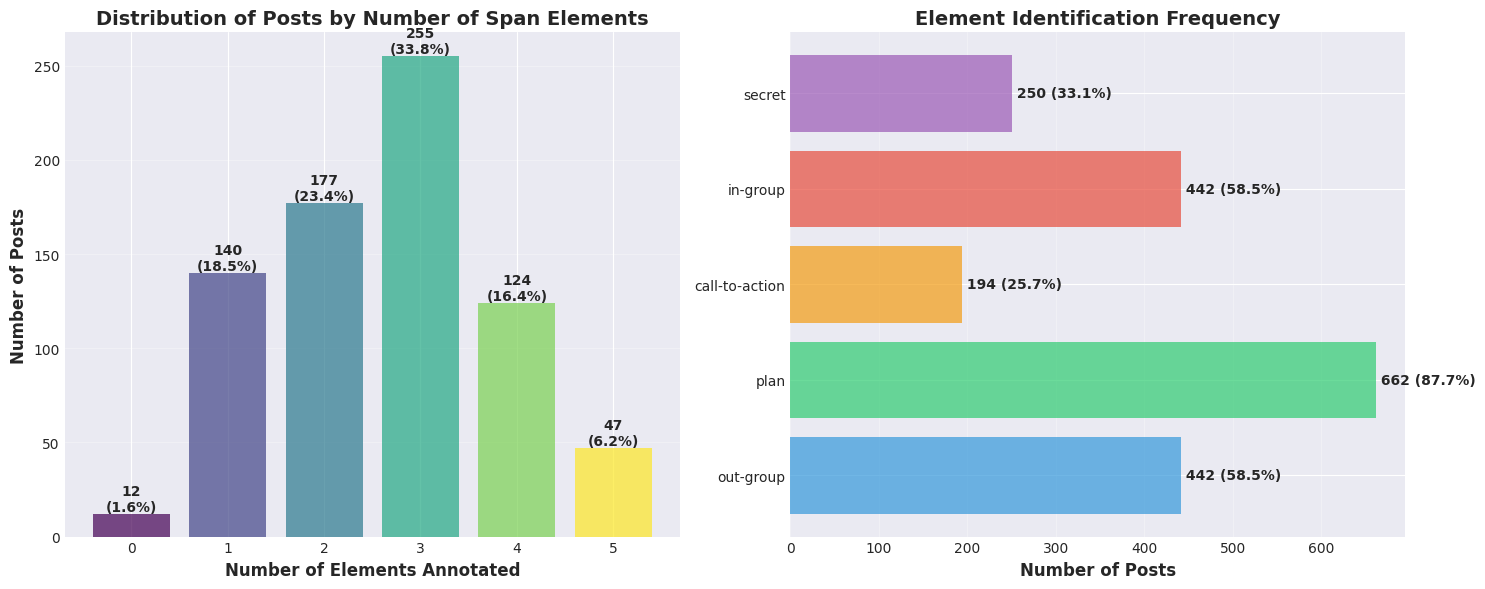

In [ ]:
# Visualization: Posts by number of elements
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Distribution of posts by number of elements
element_labels = [f'{i} element{"s" if i != 1 else ""}' for i in sorted(element_counts.index)]
colors = plt.cm.viridis(np.linspace(0, 1, len(element_counts)))

bars = axes[0].bar(range(len(element_counts)), element_counts.values, color=colors, alpha=0.7)
axes[0].set_xlabel('Number of Elements Annotated', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Posts', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Posts by Number of Span Elements', fontsize=14, fontweight='bold')
axes[0].set_xticks(range(len(element_counts)))
axes[0].set_xticklabels([str(i) for i in sorted(element_counts.index)])
axes[0].grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar, val in zip(bars, element_counts.values):
    height = bar.get_height()
    pct = val / len(posts_span_summary) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Element identification frequency
element_names = list(element_identification_counts.keys())
element_counts_list = list(element_identification_counts.values())
colors2 = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']

bars2 = axes[1].barh(element_names, element_counts_list, color=colors2, alpha=0.7)
axes[1].set_xlabel('Number of Posts', fontsize=12, fontweight='bold')
axes[1].set_title('Element Identification Frequency', fontsize=14, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

# Add value labels
for bar, val in zip(bars2, element_counts_list):
    width = bar.get_width()
    pct = val / len(posts_span_summary) * 100
    axes[1].text(width, bar.get_y() + bar.get_height()/2.,
                f' {val:,} ({pct:.1f}%)', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/span_elements_analysis.png', dpi=300, bbox_inches='tight')
print('✓ Plot saved to plots/span_elements_analysis.png')
plt.show()


---

## Conspiracy Posts and Span Annotation Coverage

This section analyzes whether posts with conspiracy='yes' have corresponding span annotations, especially mandatory elements.


In [ ]:
# Load classifications data
df_classifications = pd.read_csv('Data/all_classifications.csv')

# Filter posts with conspiracy='yes'
conspiracy_yes_posts = df_classifications[df_classifications['conspiracy'] == 'yes']['text_id'].unique()
print(f"Total unique posts with conspiracy='yes': {len(conspiracy_yes_posts):,}")

# Check which of these posts have span annotations
# (using posts_span_summary from previous cell - but need to reload if running independently)
# For standalone analysis, reload span data
df_spans_reload = pd.read_csv('Data/all_span_annotations.csv')
span_elements = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']

def is_annotated(value):
    """Check if a span element is annotated (non-empty)"""
    if pd.isna(value):
        return False
    if isinstance(value, str) and value.strip() == '':
        return False
    return True

# Count annotated elements for each row
for col in span_elements:
    if col in df_spans_reload.columns:
        df_spans_reload[f'{col}_annotated'] = df_spans_reload[col].apply(is_annotated)
    else:
        df_spans_reload[f'{col}_annotated'] = False

# Create summary for posts with span annotations
posts_with_spans_ids = df_spans_reload.groupby('text_id').agg({
    'out-group_annotated': 'any',
    'plan_annotated': 'any',
    'call-to-action_annotated': 'any',
    'in-group_annotated': 'any',
    'secret_annotated': 'any'
}).reset_index()

posts_with_spans_ids['has_plan'] = posts_with_spans_ids['plan_annotated']
posts_with_spans_ids['has_secret'] = posts_with_spans_ids['secret_annotated']
posts_with_spans_ids['has_mandatory'] = posts_with_spans_ids['has_plan'] | posts_with_spans_ids['has_secret']
posts_with_spans_ids['has_any_span'] = (
    posts_with_spans_ids['out-group_annotated'] |
    posts_with_spans_ids['plan_annotated'] |
    posts_with_spans_ids['call-to-action_annotated'] |
    posts_with_spans_ids['in-group_annotated'] |
    posts_with_spans_ids['secret_annotated']
)

print(f"Unique posts with span annotations: {len(posts_with_spans_ids):,}")
print("\n✓ Data prepared for analysis!")


Total unique posts with conspiracy='yes': 543
Unique posts with span annotations: 755

✓ Data prepared for analysis!


In [ ]:
# Check coverage: conspiracy='yes' posts with span annotations
conspiracy_yes_set = set(conspiracy_yes_posts)
posts_with_spans_set = set(posts_with_spans_ids['text_id'].values)

conspiracy_yes_with_spans = conspiracy_yes_set & posts_with_spans_set
conspiracy_yes_without_spans = conspiracy_yes_set - posts_with_spans_set

print("="*60)
print("CONSPIRACY='YES' POSTS: SPAN ANNOTATION COVERAGE")
print("="*60)
print(f"\nTotal posts with conspiracy='yes': {len(conspiracy_yes_set):,}")
print(f"Posts with conspiracy='yes' that HAVE span annotations: {len(conspiracy_yes_with_spans):,}")
print(f"Posts with conspiracy='yes' that DO NOT have span annotations: {len(conspiracy_yes_without_spans):,}")

if len(conspiracy_yes_set) > 0:
    coverage_pct = len(conspiracy_yes_with_spans) / len(conspiracy_yes_set) * 100
    print(f"\nCoverage: {coverage_pct:.2f}% of conspiracy='yes' posts have span annotations")
    
    if len(conspiracy_yes_without_spans) > 0:
        print(f"\n⚠️  Missing span annotations for {len(conspiracy_yes_without_spans):,} posts")
        print(f"   Sample text_ids without spans: {list(conspiracy_yes_without_spans)[:10]}")
    else:
        print("\n✓ All conspiracy='yes' posts have span annotations!")
else:
    print("\nNo posts with conspiracy='yes' found.")


CONSPIRACY='YES' POSTS: SPAN ANNOTATION COVERAGE

Total posts with conspiracy='yes': 543
Posts with conspiracy='yes' that HAVE span annotations: 534
Posts with conspiracy='yes' that DO NOT have span annotations: 9

Coverage: 98.34% of conspiracy='yes' posts have span annotations

⚠️  Missing span annotations for 9 posts
   Sample text_ids without spans: [np.int64(22753), np.int64(23746), np.int64(23809), np.int64(21191), np.int64(21192), np.int64(22763), np.int64(23127), np.int64(22711), np.int64(23162)]


In [ ]:
# Check mandatory elements coverage for conspiracy='yes' posts
# Mandatory elements: plan OR secret (at least one must be present)

# Filter span summary to only conspiracy='yes' posts that have spans
conspiracy_yes_spans = posts_with_spans_ids[posts_with_spans_ids['text_id'].isin(conspiracy_yes_with_spans)].copy()

if len(conspiracy_yes_spans) > 0:
    has_plan = conspiracy_yes_spans['has_plan'].sum()
    has_secret = conspiracy_yes_spans['has_secret'].sum()
    has_mandatory = conspiracy_yes_spans['has_mandatory'].sum()
    missing_mandatory = len(conspiracy_yes_spans) - has_mandatory
    
    print("="*60)
    print("CONSPIRACY='YES' POSTS: MANDATORY ELEMENTS COVERAGE")
    print("="*60)
    print(f"\nPosts with conspiracy='yes' that have span annotations: {len(conspiracy_yes_spans):,}")
    print(f"\nMandatory Elements:")
    print(f"  Posts with 'plan' element: {has_plan:,} ({has_plan/len(conspiracy_yes_spans)*100:.2f}%)")
    print(f"  Posts with 'secret' element: {has_secret:,} ({has_secret/len(conspiracy_yes_spans)*100:.2f}%)")
    print(f"  Posts with at least ONE mandatory element (plan OR secret): {has_mandatory:,} ({has_mandatory/len(conspiracy_yes_spans)*100:.2f}%)")
    print(f"  Posts MISSING both mandatory elements: {missing_mandatory:,} ({missing_mandatory/len(conspiracy_yes_spans)*100:.2f}%)")
    
    if missing_mandatory > 0:
        print(f"\n⚠️  Warning: {missing_mandatory:,} posts have conspiracy='yes' but are missing mandatory elements!")
        missing_posts = conspiracy_yes_spans[~conspiracy_yes_spans['has_mandatory']]['text_id'].tolist()
        print(f"   Sample text_ids: {missing_posts[:10]}")
    else:
        print("\n✓ All conspiracy='yes' posts with spans have at least one mandatory element!")
        
    # Check if mandatory elements are present for ALL conspiracy='yes' posts (including those without spans)
    total_conspiracy_yes = len(conspiracy_yes_set)
    conspiracy_yes_with_mandatory = len(conspiracy_yes_spans[conspiracy_yes_spans['has_mandatory']])
    conspiracy_yes_total_missing = total_conspiracy_yes - conspiracy_yes_with_mandatory
    
    print(f"\n" + "="*60)
    print(f"OVERALL COVERAGE (including posts without spans):")
    print(f"  Total posts with conspiracy='yes': {total_conspiracy_yes:,}")
    print(f"  Posts with mandatory elements: {conspiracy_yes_with_mandatory:,} ({conspiracy_yes_with_mandatory/total_conspiracy_yes*100:.2f}%)")
    print(f"  Posts missing mandatory elements or spans: {conspiracy_yes_total_missing:,} ({conspiracy_yes_total_missing/total_conspiracy_yes*100:.2f}%)")
else:
    print("No conspiracy='yes' posts with span annotations found.")


CONSPIRACY='YES' POSTS: MANDATORY ELEMENTS COVERAGE

Posts with conspiracy='yes' that have span annotations: 534

Mandatory Elements:
  Posts with 'plan' element: 473 (88.58%)
  Posts with 'secret' element: 200 (37.45%)
  Posts with at least ONE mandatory element (plan OR secret): 504 (94.38%)
  Posts MISSING both mandatory elements: 30 (5.62%)

⚠️  Warning: 30 posts have conspiracy='yes' but are missing mandatory elements!
   Sample text_ids: [21186, 21189, 21320, 22019, 22072, 22709, 22720, 22775, 22792, 22796]

OVERALL COVERAGE (including posts without spans):
  Total posts with conspiracy='yes': 543
  Posts with mandatory elements: 504 (92.82%)
  Posts missing mandatory elements or spans: 39 (7.18%)


✓ Plot saved to plots/conspiracy_span_coverage.png


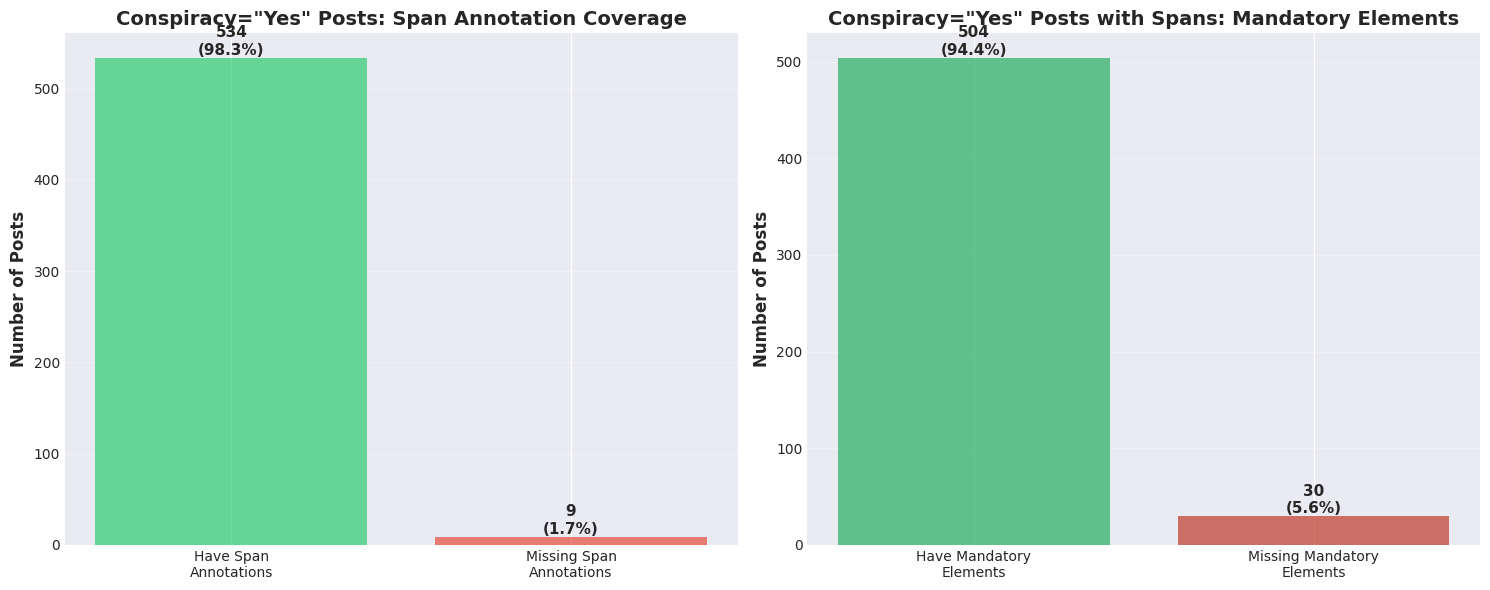

In [ ]:
# Visualization: Coverage analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Span annotation coverage for conspiracy='yes' posts
coverage_data = {
    'Have Span\nAnnotations': len(conspiracy_yes_with_spans),
    'Missing Span\nAnnotations': len(conspiracy_yes_without_spans)
}
colors1 = ['#2ecc71', '#e74c3c']

bars1 = axes[0].bar(coverage_data.keys(), coverage_data.values(), color=colors1, alpha=0.7)
axes[0].set_ylabel('Number of Posts', fontsize=12, fontweight='bold')
axes[0].set_title('Conspiracy="Yes" Posts: Span Annotation Coverage', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

for bar, (label, val) in zip(bars1, coverage_data.items()):
    height = bar.get_height()
    pct = val / len(conspiracy_yes_set) * 100 if len(conspiracy_yes_set) > 0 else 0
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Plot 2: Mandatory elements coverage (for posts with spans)
if len(conspiracy_yes_spans) > 0:
    mandatory_data = {
        'Have Mandatory\nElements': conspiracy_yes_spans['has_mandatory'].sum(),
        'Missing Mandatory\nElements': (~conspiracy_yes_spans['has_mandatory']).sum()
    }
    colors2 = ['#27ae60', '#c0392b']
    
    bars2 = axes[1].bar(mandatory_data.keys(), mandatory_data.values(), color=colors2, alpha=0.7)
    axes[1].set_ylabel('Number of Posts', fontsize=12, fontweight='bold')
    axes[1].set_title('Conspiracy="Yes" Posts with Spans: Mandatory Elements', fontsize=14, fontweight='bold')
    axes[1].grid(axis='y', alpha=0.3)
    
    for bar, (label, val) in zip(bars2, mandatory_data.items()):
        height = bar.get_height()
        pct = val / len(conspiracy_yes_spans) * 100
        axes[1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/conspiracy_span_coverage.png', dpi=300, bbox_inches='tight')
print('✓ Plot saved to plots/conspiracy_span_coverage.png')
plt.show()


res

In [ ]:
# Prepare data for span agreement analysis
# Filter to conspiracy='yes' posts with exactly 2 annotators

# Load classifications
df_classifications = pd.read_csv('Data/all_classifications.csv')

# Filter posts with conspiracy='yes'
conspiracy_yes_classifications = df_classifications[df_classifications['conspiracy'] == 'yes'].copy()

# Find posts with exactly 2 annotators (for conspiracy='yes')
posts_annotator_count = conspiracy_yes_classifications.groupby('text_id')['annotator_id'].nunique().reset_index(name='num_annotators')
posts_with_2_annotators = posts_annotator_count[posts_annotator_count['num_annotators'] == 2]['text_id'].values

# Filter classifications to conspiracy='yes' posts with 2 annotators
df_conspiracy_yes_2annot = conspiracy_yes_classifications[
    conspiracy_yes_classifications['text_id'].isin(posts_with_2_annotators)
].copy()

print(f"Total posts with conspiracy='yes': {conspiracy_yes_classifications['text_id'].nunique():,}")
print(f"Posts with conspiracy='yes' and exactly 2 annotators: {len(posts_with_2_annotators):,}")
print(f"Total annotations for these posts: {len(df_conspiracy_yes_2annot):,}")
print("\n✓ Data prepared for span agreement analysis!")


Total posts with conspiracy='yes': 543
Posts with conspiracy='yes' and exactly 2 annotators: 126
Total annotations for these posts: 252

✓ Data prepared for span agreement analysis!


In [ ]:
# Load span annotations and merge with classifications
df_spans_agreement = pd.read_csv('Data/all_span_annotations.csv')
span_elements = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']

# Function to check if annotated
def is_annotated(value):
    if pd.isna(value):
        return False
    if isinstance(value, str) and value.strip() == '':
        return False
    return True

# Mark which elements are annotated
for elem in span_elements:
    if elem in df_spans_agreement.columns:
        df_spans_agreement[f'{elem}_annotated'] = df_spans_agreement[elem].apply(is_annotated)
    else:
        df_spans_agreement[f'{elem}_annotated'] = False

# Merge span annotations with classifications to get annotator info
# We need text_id and annotator_id to match
df_spans_merged = df_spans_agreement.merge(
    df_conspiracy_yes_2annot[['text_id', 'annotator_id']],
    on=['text_id', 'annotator_id'],
    how='inner'
)

print(f"Span annotation records merged with conspiracy='yes' posts (2 annotators): {len(df_spans_merged):,}")
print(f"Unique posts in merged data: {df_spans_merged['text_id'].nunique():,}")
print("\n✓ Span data merged with classifications!")


Span annotation records merged with conspiracy='yes' posts (2 annotators): 246
Unique posts in merged data: 126

✓ Span data merged with classifications!


In [ ]:
# Calculate agreement for each span element
from sklearn.metrics import cohen_kappa_score

def calculate_span_agreement(group, elem_col):
    """
    Calculate agreement for a span element between 2 annotators.
    Returns agreement status and kappa score.
    """
    if len(group) != 2:
        return pd.Series({'agreement': 'Error', 'kappa': None})
    
    values = group[elem_col].values
    annotator1 = values[0]
    annotator2 = values[1]
    
    # Both annotated (True) or both didn't annotate (False) = Agree
    if annotator1 == annotator2:
        agreement = 'Agree'
    else:
        agreement = 'Disagree'
    
    # Calculate Cohen's Kappa
    try:
        # Convert boolean to int for kappa calculation
        y1 = [1 if annotator1 else 0]
        y2 = [1 if annotator2 else 0]
        # Kappa requires at least 2 samples, so we'll calculate for the pair
        # Use labels parameter to handle single class case
        kappa = cohen_kappa_score(y1, y2, labels=[0, 1])
        if pd.isna(kappa):
            kappa = 1.0 if agreement == 'Agree' else 0.0
    except:
        kappa = 1.0 if agreement == 'Agree' else 0.0
    
    return pd.Series({'agreement': agreement, 'kappa': kappa})

# Calculate agreement for each span element
span_agreement_results = {}

for elem in span_elements:
    elem_col = f'{elem}_annotated'
    
    if elem_col not in df_spans_merged.columns:
        continue
    
    # Group by text_id and calculate agreement
    agreement_data = df_spans_merged.groupby('text_id').apply(
        lambda x: calculate_span_agreement(x, elem_col)
    ).reset_index()
    
    agreement_data.columns = ['text_id', 'agreement', 'kappa']
    
    span_agreement_results[elem] = agreement_data

print("="*60)
print("SPAN ELEMENT AGREEMENT CALCULATED")
print("="*60)
print(f"\nAgreement computed for {len(span_agreement_results)} span elements")
print(f"Elements analyzed: {list(span_agreement_results.keys())}")


SPAN ELEMENT AGREEMENT CALCULATED

Agreement computed for 5 span elements
Elements analyzed: ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']


In [ ]:
# Aggregate agreement statistics for each span element
print("="*60)
print("INTER-ANNOTATOR AGREEMENT: SPAN ELEMENTS")
print("="*60)
print("\nAgreement statistics for each span element (conspiracy='yes' posts with 2 annotators):\n")

span_agreement_stats = {}

for elem, agreement_df in span_agreement_results.items():
    total_posts = len(agreement_df)
    agree_count = len(agreement_df[agreement_df['agreement'] == 'Agree'])
    disagree_count = len(agreement_df[agreement_df['agreement'] == 'Disagree'])
    agree_pct = (agree_count / total_posts * 100) if total_posts > 0 else 0
    
    # Calculate average kappa
    valid_kappas = agreement_df['kappa'].dropna()
    avg_kappa = valid_kappas.mean() if len(valid_kappas) > 0 else 0
    
    span_agreement_stats[elem] = {
        'total_posts': total_posts,
        'agree': agree_count,
        'disagree': disagree_count,
        'agree_pct': agree_pct,
        'avg_kappa': avg_kappa
    }
    
    print(f"{elem:20s}:")
    print(f"  Total posts analyzed: {total_posts:,}")
    print(f"  Agreement: {agree_count:,} posts ({agree_pct:.2f}%)")
    print(f"  Disagreement: {disagree_count:,} posts ({100-agree_pct:.2f}%)")
    print(f"  Average Cohen's Kappa: {avg_kappa:.3f}")
    print()

# Sort by agreement percentage
sorted_by_agreement = sorted(span_agreement_stats.items(), key=lambda x: x[1]['agree_pct'], reverse=True)

print("-" * 60)
print("Ranked by Agreement Rate:")
print("-" * 60)
for i, (elem, stats) in enumerate(sorted_by_agreement, 1):
    print(f"{i}. {elem:20s}: {stats['agree_pct']:.2f}% agreement (κ={stats['avg_kappa']:.3f})")


INTER-ANNOTATOR AGREEMENT: SPAN ELEMENTS

Agreement statistics for each span element (conspiracy='yes' posts with 2 annotators):

out-group           :
  Total posts analyzed: 126
  Agreement: 86 posts (68.25%)
  Disagreement: 34 posts (31.75%)
  Average Cohen's Kappa: 0.717

plan                :
  Total posts analyzed: 126
  Agreement: 97 posts (76.98%)
  Disagreement: 23 posts (23.02%)
  Average Cohen's Kappa: 0.808

call-to-action      :
  Total posts analyzed: 126
  Agreement: 90 posts (71.43%)
  Disagreement: 30 posts (28.57%)
  Average Cohen's Kappa: 0.750

in-group            :
  Total posts analyzed: 126
  Agreement: 76 posts (60.32%)
  Disagreement: 44 posts (39.68%)
  Average Cohen's Kappa: 0.633

secret              :
  Total posts analyzed: 126
  Agreement: 82 posts (65.08%)
  Disagreement: 38 posts (34.92%)
  Average Cohen's Kappa: 0.683

------------------------------------------------------------
Ranked by Agreement Rate:
------------------------------------------------

✓ Plot saved to plots/span_elements_agreement.png


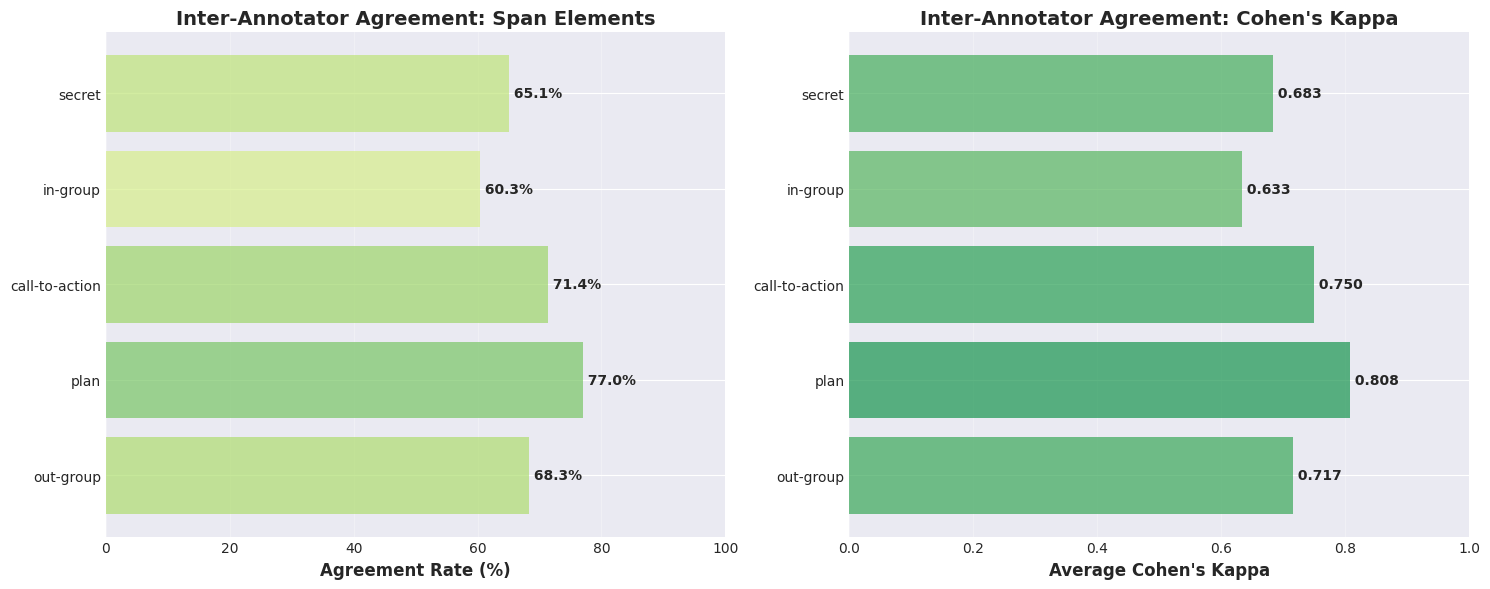

In [ ]:
# Visualization: Agreement rates for span elements
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Agreement percentages
elements = list(span_agreement_stats.keys())
agree_percentages = [span_agreement_stats[elem]['agree_pct'] for elem in elements]
colors = plt.cm.RdYlGn([x/100 for x in agree_percentages])  # Green for high, red for low

bars = axes[0].barh(elements, agree_percentages, color=colors, alpha=0.7)
axes[0].set_xlabel('Agreement Rate (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Inter-Annotator Agreement: Span Elements', fontsize=14, fontweight='bold')
axes[0].set_xlim(0, 100)
axes[0].grid(axis='x', alpha=0.3)

# Add value labels
for bar, pct in zip(bars, agree_percentages):
    width = bar.get_width()
    axes[0].text(width, bar.get_y() + bar.get_height()/2.,
                f' {pct:.1f}%', ha='left', va='center', fontsize=10, fontweight='bold')

# Plot 2: Average Cohen's Kappa
kappa_values = [span_agreement_stats[elem]['avg_kappa'] for elem in elements]
colors2 = plt.cm.RdYlGn([max(0, min(1, (k + 1) / 2)) for k in kappa_values])

bars2 = axes[1].barh(elements, kappa_values, color=colors2, alpha=0.7)
axes[1].set_xlabel("Average Cohen's Kappa", fontsize=12, fontweight='bold')
axes[1].set_title("Inter-Annotator Agreement: Cohen's Kappa", fontsize=14, fontweight='bold')
axes[1].set_xlim(0, 1)
axes[1].grid(axis='x', alpha=0.3)

# Add value labels
for bar, kappa in zip(bars2, kappa_values):
    width = bar.get_width()
    axes[1].text(width, bar.get_y() + bar.get_height()/2.,
                f' {kappa:.3f}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/span_elements_agreement.png', dpi=300, bbox_inches='tight')
print('✓ Plot saved to plots/span_elements_agreement.png')
plt.show()


In [ ]:
# Detailed agreement breakdown: Agreement counts for each element
print("="*60)
print("DETAILED AGREEMENT COUNTS BY ELEMENT")
print("="*60)

# Create a summary DataFrame
summary_data = []
for elem, stats in span_agreement_stats.items():
    summary_data.append({
        'Element': elem,
        'Total Posts': stats['total_posts'],
        'Agree': stats['agree'],
        'Disagree': stats['disagree'],
        'Agreement %': stats['agree_pct'],
        'Avg Kappa': stats['avg_kappa']
    })

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values('Agreement %', ascending=False)

print("\nSummary Table:")
print(summary_df.to_string(index=False))
print("\n" + "="*60)


DETAILED AGREEMENT COUNTS BY ELEMENT

Summary Table:
       Element  Total Posts  Agree  Disagree  Agreement %  Avg Kappa
          plan          126     97        23    76.984127   0.808333
call-to-action          126     90        30    71.428571   0.750000
     out-group          126     86        34    68.253968   0.716667
        secret          126     82        38    65.079365   0.683333
      in-group          126     76        44    60.317460   0.633333

